# Greek Life Language Variation: Survey Analysis
**LING 3442: Sociolinguistic survey of Boston-area fraternity and sorority speech (n=20)**

**Research goal:** to explore the linguistic patterns and Greek-life-specific lexicon of fraternity and sorority members, and to test for variation by gender, chapter affiliation, race, ethnicity, and age. 

**Hypothesis:** an in-group (Greek) / out-group (non-Greek) dynamic in vocabulary, with sub-varieties inside the in-group, including separate sorority and fraternity vernaculars.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#efede8", "grid.linewidth": 0.8, "figure.facecolor": "white",
    "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold",
    "axes.edgecolor": "#c9c6bd", "xtick.color": "#5f5d57", "ytick.color": "#5f5d57", "axes.titlesize": 11,
    "axes.labelcolor": "#3d3b37", "axes.titlecolor": "#2b2a27", "legend.frameon": False,
})

# color per group
GROUP_ORDER = ["Sorority", "Fraternity", "Non-Greek"]
GROUP_COLORS = {"Sorority": "#2A9D8F", "Fraternity": "#3A5DA8", "Non-Greek": "#E9A23B"}
ACCENT = "#4A5A70"   # slate, for single-series charts
VARIANT_COLORS = ["#4A5A70", "#B08E66", "#B7C6D8", "#56735F", "#E8E3DA"]

from matplotlib.colors import LinearSegmentedColormap
SEQ_CMAP = LinearSegmentedColormap.from_list("soft_blue", ["#f4faf8", "#8fd0c6", "#1f6f66"])
TIER_ORDER = ["Core member", "Peripheral member", "Non-Greek"]
TIER_COLORS = {"Core member": "#4A5A70", "Peripheral member": "#A7B1BF", "Non-Greek": "#E9A23B"}

DATA_PATH = "Sociolinguistic_Survey__Greek_Life_Responses.xlsx" 

# 1. Load and clean the data
Using the classified sheet, drop legend row, fix typos, create a group variable (sorority/fraternity/non-greek) and turn ordinal answers into numbers.

In [2]:
raw = pd.read_excel(DATA_PATH, sheet_name="classified")
cols = ["timestamp", "year", "gender", "race", "ethnicity", "university", "member", "chapter",
        "tenure", "hours", "position", "circle", "alphabet",
        "assoc_frat", "assoc_soro", "talk_ingroup",
        "join_process", "reputation", "new_member", "one_frat_one_soro", "multi_soro",
        "pledge_class", "ferda", "booling", "hell_week"]
df = raw.copy()
df.columns = cols
df = df[df["timestamp"].notna()].reset_index(drop=True) # drop legend row

def fix_labels(s):
    if pd.isna(s): return s
    s = str(s).strip()
    s = re.sub(r"\bU(k|n)n?own\b|\bUknown\b|\bUnkown\b", "Unknown", s)
    s = s.replace("Insitiutional", "Institutional").replace(")l ", "); ")
    return s
for c in cols[13:]:
    df[c] = df[c].map(fix_labels)

df["group"] = np.where(df["member"].eq("Yes"),
                       np.where(df["gender"].eq("Female"), "Sorority", "Fraternity"), "Non-Greek")
df["year_num"] = df["year"].str.extract(r"(\d)").astype(float)
sem_map = {"first": 1, "third": 3, "fifth": 5, "seventh": 7, "ninth": 9}
df["semesters"] = df["tenure"].str.lower().map(
    lambda t: next((v for k, v in sem_map.items() if isinstance(t, str) and k in t), np.nan))
df["hours_num"] = df["hours"].map({"1-2 hours per week": 1.5, "3-4 hours per week": 3.5,
                                   "5-6 hours per week": 5.5, "7+ hours per week": 7.5})
df["position"] = pd.to_numeric(df["position"], errors="coerce")   # 0 new mem … 4 exec
# clean up spelling and spacing
df["race_clean"] = df["race"].map(lambda s: "Not reported" if pd.isna(s) else s.strip()[0].upper() + s.strip()[1:])
print(f"{len(df)} respondents loaded")
df[["year", "gender", "group", "chapter", "semesters", "hours", "position", "circle", "alphabet"]].head()

20 respondents loaded


,year,gender,group,chapter,semesters,hours,position,circle,alphabet
0,3rd year,Male,Fraternity,Zeta Beta Tau,NaN,3-4 hours per week,1.0,3.0,5.0
1,1st year,Male,Fraternity,Zeta Beta Tau,1.0,1-2 hours per week,0.0,4.0,4.0
2,1st year,Male,Fraternity,Zeta Beta Tau,1.0,3-4 hours per week,0.0,3.0,3.0
3,2nd year,Male,Fraternity,Zeta Beta Tau,1.0,5-6 hours per week,0.0,1.0,5.0
4,2nd year,Male,Fraternity,Zeta Beta Tau,1.0,3-4 hours per week,0.0,3.0,5.0


# 2. Sample

In [3]:
def counts(col, order=None):
    t = df[col].value_counts(dropna=False)
    if order: t = t.reindex(order).fillna(0).astype(int)
    return t
summary = pd.concat({
    "Group": counts("group", GROUP_ORDER),
    "Year": counts("year", ["1st year", "2nd year", "3rd year", "4th year", "5th year"]),
    "Race (as reported)": counts("race_clean"),
    "Chapter": df["chapter"].fillna("— (Non-Greek)").value_counts(),
}).rename("n").to_frame()
summary["%"] = (summary["n"] / len(df) * 100).round(0).astype(int)
display(summary)

n   %
Group              Sorority                     10  50
                   Fraternity                    6  30
                   Non-Greek                     4  20
Year               1st year                      2  10
                   2nd year                      5  25
                   3rd year                      5  25
                   4th year                      6  30
                   5th year                      2  10
Race (as reported) White                         9  45
                   Latina                        2  10
                   Asian                         1   5
                   Asian American                1   5
                   Mixed                         1   5
                   Caucasian                     1   5
                   White/middle eastern          1   5
                   Biracial                      1   5
                   Mixed race(black and white)   1   5
                   East Asian                    1   5
                   Not reported                  1   5
Chapter            Delta Phi Epsilon             7  35
                   Zeta Beta Tau                 5  25
                   — (Non-Greek)                 4  20
                   Sigma Delta Tau               1   5
                   Sigma Sigma Sigma             1   5
                   Sigma Kappa                   1   5
                   Alpha Epsilon Pi              1   5

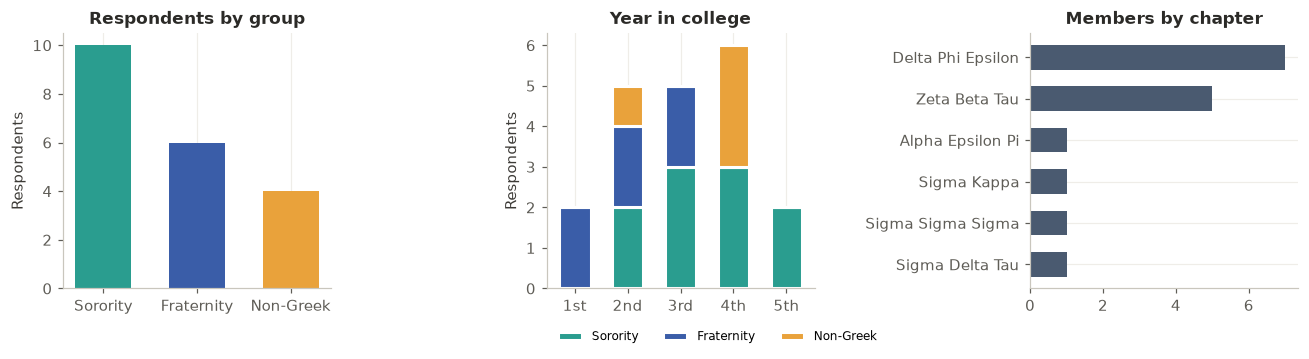

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
g = counts("group", GROUP_ORDER)
axes[0].bar(g.index, g.values, color=[GROUP_COLORS[k] for k in g.index], width=0.6)
axes[0].set_title("Respondents by group")
yr = pd.crosstab(df["year"], df["group"]).reindex(columns=GROUP_ORDER, fill_value=0)
bottom = np.zeros(len(yr))
for grp in GROUP_ORDER:
    axes[1].bar(yr.index.str.replace(" year", ""), yr[grp], bottom=bottom, color=GROUP_COLORS[grp],
                label=grp, width=0.6, edgecolor="white", linewidth=2)
    bottom += yr[grp].values
axes[1].set_title("Year in college"); axes[1].legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=3)
ch = df["chapter"].value_counts().sort_values()
axes[2].barh(ch.index, ch.values, color=ACCENT, height=0.6)
axes[2].set_title("Members by chapter")
for a in axes[:2]: a.set_ylabel("Respondents")
for a in axes: a.grid(axis="x" if a is axes[2] else "y")
plt.tight_layout(); plt.show()

**Notes:** 20 respondents (19 from Northeastern), 10 sorority, 6 fraternity, 4 non-Greek. Members come mainly from Delta Phi Epsilon (7) and Zeta Beta Tau (5).

# 3. Linguistic factor: type of word
Each fill-in item was scored 1 if the person gave the in-group form and 0 if not (for ferda, booling, hell week: Exact = 1, Approximate = 0.5, Unknown = 0). The average of the 8 items is each person's **in-group knowledge score (0-100)**. Items are grouped by word type: institutional, event, slang.

In [5]:
SCORING = {
    "join_process": ("Process of joining", "Institutional", lambda v: 1.0 if v == "Greek process term" else 0.0),
    "new_member":   ("Bid-holder (new member/pledge)", "Institutional", lambda v: 0.0 if v == "PNM" else 1.0),
    "pledge_class": ("Pledge class (cohort)", "Institutional", lambda v: 1.0 if v in ("Pledge Class (PC)", "Journey Class") else 0.0),
    "multi_soro":   ("Multi-sorority event (mega)", "Event term", lambda v: 1.0 if v == "Mega" else 0.0),
    "reputation":   ("Reputation (touse/bouse)", "Slang", lambda v: 1.0 if v == "Target slang" else 0.0),
    "ferda":        ("ferda", "Slang", lambda v: {"Exact": 1, "Approximate": .5}.get(v, 0.0)),
    "booling":      ("booling", "Slang", lambda v: {"Exact": 1, "Approximate": .5}.get(v, 0.0)),
    "hell_week":    ("hell week", "Slang", lambda v: {"Exact": 1, "Approximate": .5}.get(v, 0.0)),
}
score_cols = []
for col, (label, ltype, f) in SCORING.items():
    df["s_" + col] = df[col].map(f)
    score_cols.append("s_" + col)
df["knowledge_index"] = df[score_cols].mean(axis=1) * 100     # 0–100 in-group lexical knowledge

item_tbl = pd.DataFrame({
    "Item": [v[0] for v in SCORING.values()],
    "Lexical type": [v[1] for v in SCORING.values()],
    "Mean score (all, %)": [df["s_" + c].mean() * 100 for c in SCORING],
}).set_index("Item")
for grp in GROUP_ORDER:
    item_tbl[grp + " %"] = [df.loc[df.group == grp, "s_" + c].mean() * 100 for c in SCORING]
item_tbl = item_tbl.sort_values("Mean score (all, %)", ascending=False).round(0)
display(item_tbl)

,Lexical type,"Mean score (all, %)",Sorority %,Fraternity %,Non-Greek %
Item,,,,,
Bid-holder (new member/pledge),Institutional,90.0,90.0,83.0,100.0
Pledge class (cohort),Institutional,90.0,100.0,67.0,100.0
hell week,Slang,80.0,75.0,92.0,75.0
booling,Slang,50.0,30.0,58.0,88.0
Process of joining,Institutional,40.0,40.0,33.0,50.0
ferda,Slang,40.0,45.0,25.0,50.0
Multi-sorority event (mega),Event term,25.0,40.0,0.0,25.0
Reputation (touse/bouse),Slang,20.0,20.0,0.0,50.0


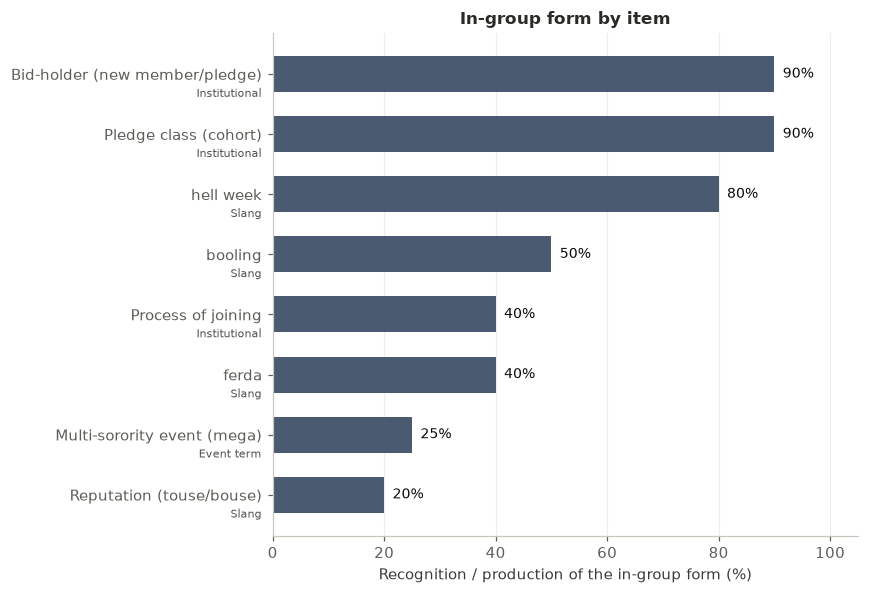

In [6]:
order = item_tbl.index[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(order, item_tbl.loc[order, "Mean score (all, %)"], color=ACCENT, height=0.6)
for y, v in enumerate(item_tbl.loc[order, "Mean score (all, %)"]):
    ax.text(v + 1.5, y, f"{v:.0f}%", va="center", fontsize=9, color="#0b0b0b")
for y, item in enumerate(order):
    ax.text(-2, y - 0.38, item_tbl.loc[item, "Lexical type"], ha="right", fontsize=7.5, color="#52514e")
ax.set_xlim(0, 105); ax.set_xlabel("Recognition / production of the in-group form (%)")
ax.set_title("In-group form by item"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Notes:** Institutional words are known by almost everyone (pledge class, new member/pledge: 90%). Slang is much more uneven: hell week is widely known (or potentially inferred) (80%), but booling (50%), ferda (40%), and touse/bouse (20%) drop off, as does the event term mega (25%). Only 2 respondents gave the exact response for ferda = "for the boys". Institutional Greek words can be assumed to be common campus knowledge, while slang and subgroup words are where in-group vocabulary is delineated.

# Open-ended associations: words linked to fraternities vs sororities

In [7]:
CLASSES = ["-ouse tier terms", "Slang", "Events/party", "Institutional", "Kinship", "Evaluative", "Chapter names"]
def parse_codes(s):
    out = {}
    if pd.isna(s): return out
    for m in re.finditer(r"([A-Za-z/\- ]+?)\s*\((\d+)\)", s):
        out[m.group(1).strip()] = out.get(m.group(1).strip(), 0) + int(m.group(2))
    return out
assoc = {}
for col, target in [("assoc_frat", "Fraternities"), ("assoc_soro", "Sororities")]:
    parsed = df[col].map(parse_codes)
    m = pd.DataFrame(list(parsed)).reindex(columns=CLASSES).fillna(0)
    assoc[target] = m
assoc_tbl = pd.DataFrame({
    ("Fraternities", "respondents"): (assoc["Fraternities"] > 0).sum(),
    ("Fraternities", "words"):       assoc["Fraternities"].sum(),
    ("Sororities", "respondents"):   (assoc["Sororities"] > 0).sum(),
    ("Sororities", "words"):         assoc["Sororities"].sum(),
}).astype(int)
display(assoc_tbl)

Fraternities        Sororities      
                  respondents words respondents words
-ouse tier terms            9    22           1     3
Slang                       7    16           1     1
Events/party                8    14           2     5
Institutional               7    10          10    22
Kinship                     6     8          14    23
Evaluative                  3     6           6    10
Chapter names               1     5           0     0

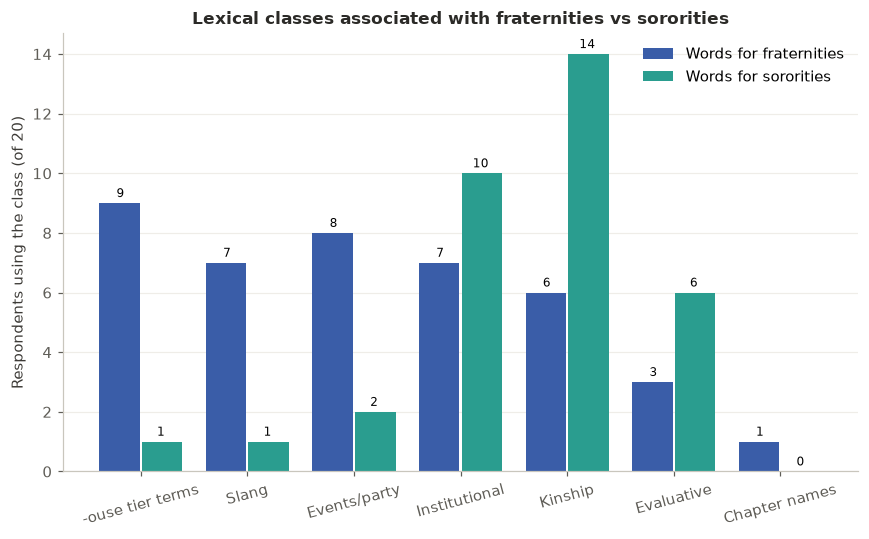

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(CLASSES)); w = 0.38
fr = (assoc["Fraternities"] > 0).sum(); so = (assoc["Sororities"] > 0).sum()
ax.bar(x - w/2 - 0.01, fr.values, w, color=GROUP_COLORS["Fraternity"], label="Words for fraternities")
ax.bar(x + w/2 + 0.01, so.values, w, color=GROUP_COLORS["Sorority"], label="Words for sororities")
for xi, (a, b) in enumerate(zip(fr.values, so.values)):
    ax.text(xi - w/2, a + 0.2, int(a), ha="center", fontsize=8); ax.text(xi + w/2, b + 0.2, int(b), ha="center", fontsize=8)
ax.set_xticks(x, CLASSES, rotation=15); ax.set_ylabel("Respondents using the class (of 20)")
ax.set_title("Lexical classes associated with fraternities vs sororities"); ax.legend(frameon=False)
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

In [9]:
# Who produced each class?  Respondents using the class, broken down by the respondent's own group
who = {}
for target in ["Fraternities", "Sororities"]:
    used = assoc[target] > 0
    who[target] = pd.DataFrame({g: used[df.group.eq(g)].sum() for g in GROUP_ORDER}).astype(int)
display(pd.concat(who, axis=1))

Fraternities                      Sororities             \
                     Sorority Fraternity Non-Greek   Sorority Fraternity   
-ouse tier terms            6          2         1          1          0   
Slang                       2          3         2          0          1   
Events/party                5          2         1          1          1   
Institutional               4          0         3          8          0   
Kinship                     3          3         0          9          2   
Evaluative                  1          2         0          3          3   
Chapter names               1          0         0          0          0   

                            
                 Non-Greek  
-ouse tier terms         0  
Slang                    0  
Events/party             0  
Institutional            2  
Kinship                  3  
Evaluative               0  
Chapter names            0

**Notes:** Fraternities are linked to ranking slang and party words (touse/bouse, ferda, sendy, darty). Sororities are linked to kinship and institutional words (sisterhood, big/little, PNM, Panhel). 6 of 9 people who listed -ouse terms for fraternities are sorority members, so frat ranking vocabulary circulates mostly among women.

# 4. Social factors

### 4a. Group: sorority vs fraternity vs non-Greek

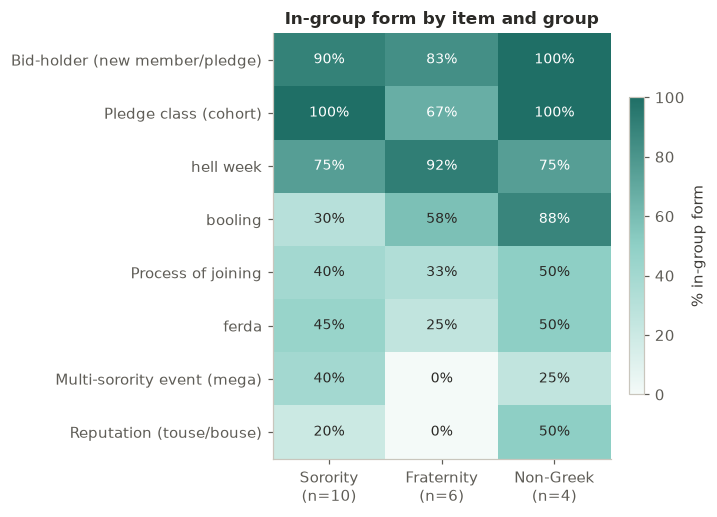

In [10]:
heat = item_tbl[[g + " %" for g in GROUP_ORDER]].copy()
heat.columns = GROUP_ORDER
fig, ax = plt.subplots(figsize=(6.6, 4.8))
im = ax.imshow(heat.values, cmap=SEQ_CMAP, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(3), [f"{g}\n(n={(df.group==g).sum()})" for g in GROUP_ORDER])
ax.set_yticks(range(len(heat)), heat.index); ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white" if v > 65 else "#2b2a27")
ax.set_title("In-group form by item and group")
fig.colorbar(im, ax=ax, fraction=0.04, label="% in-group form")
plt.tight_layout(); plt.show()

In [11]:
ki = df.groupby("group")["knowledge_index"].agg(["count", "mean"]).reindex(GROUP_ORDER).round(0)
ki.columns = ["n", "Average knowledge score"]
display(ki)

,n,Average knowledge score
group,,
Sorority,10,55.0
Fraternity,6,45.0
Non-Greek,4,67.0


**Notes:** Non-Greek respondents scored highest (67 vs 55 sorority, 45 fraternity), which goes against the in-group/out-group hypothesis. There are only 4 non-Greek and 3 are 4th-years, so they are likely to have picked it up as general student slang. Sorority members lead on pledge class and mega, while fraternity members lead on hell week and booling.

### 4b. Gendered variants: different term based on gender

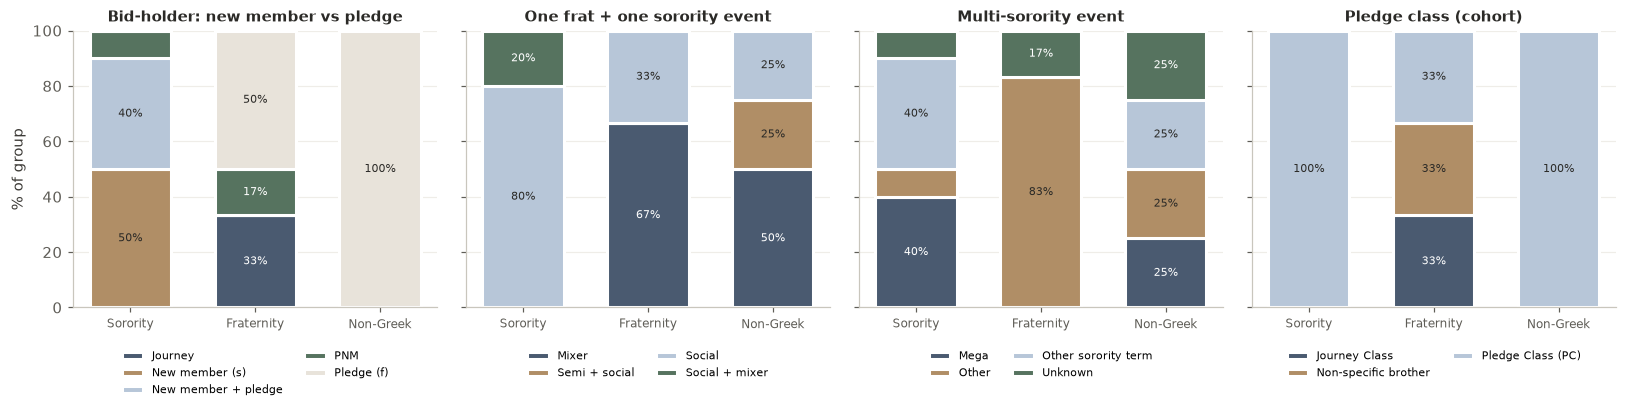

In [12]:
VARIANT_ITEMS = {
    "new_member": "Bid-holder: new member vs pledge",
    "one_frat_one_soro": "One frat + one sorority event",
    "multi_soro": "Multi-sorority event",
    "pledge_class": "Pledge class (cohort)",
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), sharey=True)
for ax, (col, title) in zip(axes, VARIANT_ITEMS.items()):
    ct = pd.crosstab(df[col], df["group"]).reindex(columns=GROUP_ORDER, fill_value=0)
    pct = ct / ct.sum() * 100
    cats = list(pct.index)
    shades = VARIANT_COLORS[:len(cats)]
    bottom = np.zeros(3)
    for cat, colr in zip(cats, shades):
        ax.bar(GROUP_ORDER, pct.loc[cat], bottom=bottom, color=colr, label=cat, width=0.65,
               edgecolor="white", linewidth=2)
        for xi, (b, v) in enumerate(zip(bottom, pct.loc[cat])):
            if v >= 12: ax.text(xi, b + v/2, f"{v:.0f}%", ha="center", va="center", fontsize=7.5,
                                    color="#2b2a27" if colr in ("#B08E66", "#B7C6D8", "#E8E3DA") else "white")
        bottom += pct.loc[cat].values
    ax.set_title(title, fontsize=9.5); ax.legend(frameon=False, fontsize=7, loc="upper center",
                                                  bbox_to_anchor=(0.5, -0.12), ncol=2)
    ax.tick_params(axis="x", labelsize=8); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of group")
plt.tight_layout(); plt.show()

**Notes:** supports gendered vernacular hypothesis:
* **New member vs pledge:** 9/10 soririty members say new member; 0/6 fraternity members do. All non-Greek say pledge.
* **Social vs mixer:** 10/10 sorority members say social; 4/6 fraternity members say mixer
* **Mega:** 4/10 sorority members; 0 fraternity
* **Pledge class:** shared, except ZBT's journey class

### 4c. Core vs peripheral members (involvement)
*core* = leadership position or mostly Greek friend circle (4-5). *peripheral* = other members.

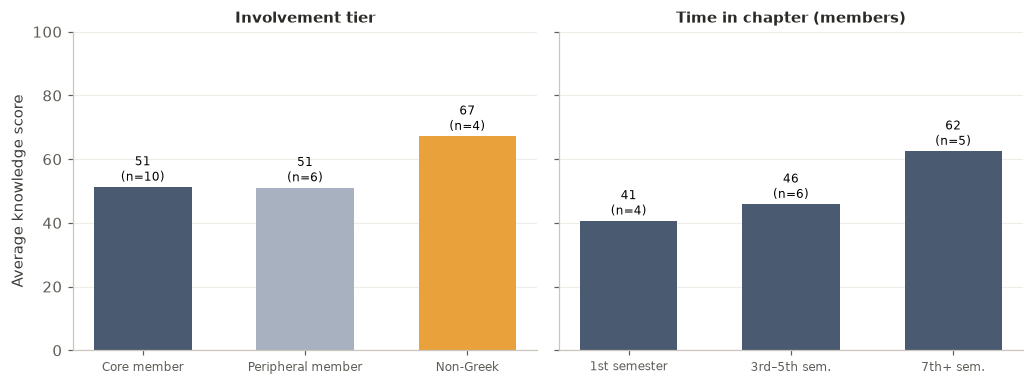

In [13]:
df["tier"] = np.where(df.member.eq("No"), "Non-Greek",
                      np.where((df.position >= 2) | (df.circle >= 4), "Core member", "Peripheral member"))
df["tenure_grp"] = pd.cut(df["semesters"], [0, 1, 5, 9], labels=["1st semester", "3rd–5th sem.", "7th+ sem."])
panels = [("tier", "Involvement tier", TIER_ORDER), ("tenure_grp", "Time in chapter (members)", None)]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
for ax, (col, title, order) in zip(axes, panels):
    t = df.groupby(col, observed=True)["knowledge_index"].agg(["mean", "size"])
    if order: t = t.reindex(order)
    colors = [TIER_COLORS[i] for i in t.index] if order else ACCENT
    ax.bar(t.index.astype(str), t["mean"], color=colors, width=0.6)
    for x, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(x, m + 2, f"{m:.0f}\n(n={n})", ha="center", fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylim(0, 100); ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("Average knowledge score")
plt.tight_layout(); plt.show()

**Notes:** Core and peripheral members score the same, and friend circle made no difference either. *Time* makes scores rise from 41 (1st semester) to 62 (7th+). Exposure over time, not intensity of involvement, build the vocabulary.

### 4d. Chapter and race

In [14]:
ch_tbl = (df[df.member == "Yes"].groupby("chapter")
          .agg(n=("knowledge_index", "size"), mean_score=("knowledge_index", "mean"),
               says_journey_class=("pledge_class", lambda s: (s == "Journey Class").sum()),
               says_mega=("multi_soro", lambda s: (s == "Mega").sum()))
          .sort_values("n", ascending=False).round(0))
race_tbl = df.groupby("race_clean").agg(n=("knowledge_index", "size"),
                                        mean_score=("knowledge_index", "mean")).sort_values("n", ascending=False).round(0)
display(ch_tbl); display(race_tbl)

,n,mean_score,says_journey_class,says_mega
chapter,,,,
Delta Phi Epsilon,7,49.0,0,3
Zeta Beta Tau,5,46.0,2,0
Alpha Epsilon Pi,1,38.0,0,0
Sigma Delta Tau,1,88.0,0,0
Sigma Kappa,1,44.0,0,1
Sigma Sigma Sigma,1,75.0,0,0


,n,mean_score
race_clean,,
White,9,58.0
Latina,2,50.0
Asian,1,31.0
Asian American,1,38.0
Biracial,1,62.0
Caucasian,1,75.0
East Asian,1,25.0
Mixed,1,56.0
Mixed race(black and white),1,50.0


**Notes:** 
* **Chapter:** *journey class* appears only in ZBT, and DPhiE gives most of the *mega* answers.
* **Race (as self-reported):** apart from White (9), every category has 1-2 people, so no comparison is possible.

### 4e. How people say Greek talk differs (coded themes)

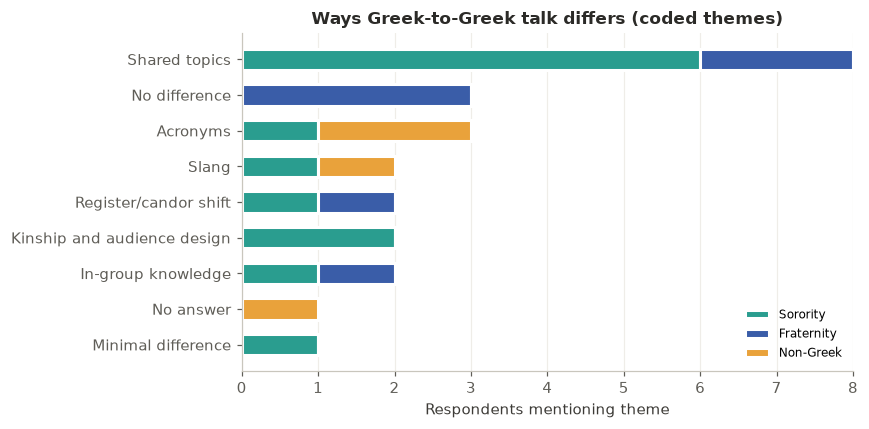

In [15]:
theme_df = (df.assign(theme=df["talk_ingroup"].fillna("No answer").str.split(";"))
              .explode("theme")[["theme", "group"]].reset_index(drop=True))
theme_df["theme"] = theme_df["theme"].str.strip()
tt = pd.crosstab(theme_df.theme, theme_df.group).reindex(columns=GROUP_ORDER, fill_value=0)
tt["Total"] = tt.sum(axis=1); tt = tt.sort_values("Total")

fig, ax = plt.subplots(figsize=(8, 4))
left = np.zeros(len(tt))
for g in GROUP_ORDER:
    ax.barh(tt.index, tt[g], left=left, color=GROUP_COLORS[g], label=g, height=0.6, edgecolor="white", linewidth=2)
    left += tt[g].values
ax.set_xlabel("Respondents mentioning theme"); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Ways Greek-to-Greek talk differs (coded themes)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Notes:** Most describe the difference as *shared topics* (events, rush, etc), not different words. All 3 'no difference' answers came from fraternity members. Speakers may be less of aware of their in-group words than the fill-in items show.

### 5. Summary
| Hypothesis | Result |
|---|---|
| In-group / out-group vocabulary | **Not supported** here: non-Greek scored highest (small, high-contact sample) |
| Separate sorority vs fraternity vernaculars | **Supported**: *new member/pledge*, *social/mixer*, *mega* |
| Chapter sub-varieties | **Supported**: ZBT's *journey class* |
| Time in Greek life | **Partly supported**: scores rise with semesters in chapter |
| Core vs peripheral members | **Not supported**: same scores |
| Race / ethnicity | **Not testable** with this sample |